# Reduced attitude control

A quadrotor's thrust direction determines the direction of its propulsive force. We consider two controllers: one aligns the thrust direction with the vertical, and the other makes it rotate around a prescribed cone. This example tests whether a learned model preserves these known behaviors when the topological computation is performed in one dimension. The learned model predicts thrust direction from full-state observations along trajectories initialized with zero angular-velocity tracking error.

## Setup

The saved outputs can be read without running Python. To reproduce them, follow the [installation instructions](README.md#install), select that environment's kernel, and run the cells in order from the repository root. Python 3.13, Graphviz (`dot`), and Poppler (`pdftoppm`) are required.

The default `MODE = "replay"` loads the validation-selected fit for each controller and recomputes its results without retraining. `MODE = "train"` instead retrains those selected seeds. `OUT = None` creates a fresh directory under `outputs/notebooks/` for numerical results and PDF/SVG figures.

The calls below use `Notebook` in [`morsegraphs/attitude_control.py`](morsegraphs/attitude_control.py). That module contains the controller (`field`, `rhs`), learned maps (`AttitudeModel`), and loss (`_pieces`). The shared modules [`grids.py`](morsegraphs/grids.py), [`regions.py`](morsegraphs/regions.py), and [`homology.py`](morsegraphs/homology.py) compute the cell graphs, attracting regions, and reconstructed indices. Model and data settings are recorded in [`config.json`](data/ex3_attitude_control/config.json).

The networks use float32, while the physical simulator, cell geometry, and index computations use binary64. Configure the device before importing JAX. NumPy handles arrays, SciPy integrates the scalar equation, and Matplotlib draws the diagnostic plots below.

In [1]:
MODE = "replay"
OUT = None

from morsegraphs import device
device.configure("float32")
from morsegraphs import attitude_control as ac
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import display

run = ac.Notebook(MODE, OUT)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
display(run)

setting,value
mode,replay
data,data/ex3_attitude_control
output folder,outputs/notebooks/ex3_attitude_control-replay-20261114-031111
selected fits,"nominal-seed0, coning-seed0 (lowest validation objective, chosen before any CMGDB computation)"
networks,"JAX 0.4.38 on cpu, float32"
CMGDB,"1.5.3+fork.7, binary64, coefficients in F_5"


## Controlled motion and physical quotient

The rigid-body state is $(p,v,R,\Omega)\in\mathbb R^3\times\mathbb R^3\times\mathrm{SO}(3)\times\mathbb R^3$. Position and velocity are $p,v$, orientation is $R$, and body angular velocity is $\Omega$. The thrust direction is $q=Re_3\in S^2$, where $e_3=(0,0,1)$. Write $z=q\cdot e_3$ and $w=R\Omega$.

For a gain $a:[-1,1]\to\mathbb R$, prescribe
$$V_a(q)=a(z)(e_3-zq)+\omega e_3\times q,\qquad \omega=\pi/\log2.$$
The first term changes the tilt, while the second rotates the thrust direction about the vertical. Both are tangent to the sphere. Define $w_d(q)=q\times V_a(q)$ and the rate error $\eta=w-w_d(q)$. With inertia matrix $J$, the control moment is
$$M=\Omega\times J\Omega+JR^\top\bigl(Dw_d(q)[w\times q]-2\eta\bigr).$$
Here $Dw_d(q)[h]$ is the directional derivative in direction $h$. For tangent $h$ it is
$$Dw_d(q)[h]=a'(z)h_3(q\times e_3)+a(z)(h\times e_3)-\omega(h_3q+zh).$$
Substitution into the rigid-body equations gives
$$\dot q=V_a(q)+\eta\times q,\qquad \dot\eta=-2\eta.$$
Thus $\eta=0$ is invariant. All training trajectories start there, so the thrust direction evolves autonomously under a flow $F_t:S^2\to S^2$. For mass $\mu$ and gravitational acceleration $g$, the thrust magnitude is fixed at $\mu g$, giving $\dot v=g(q-e_3)$. This controller regulates the thrust direction but not position, so a coning thrust direction need not produce a periodic flight path.


### Removing rotation about the vertical

For a rotation $Q\in\mathrm{SO}(2)$ about $e_3$, the state action is $(p,v,R,\Omega)\mapsto(Qp,Qv,QR,\Omega)$ and $q\mapsto Qq$. The height projection $\pi:S^2\to[-1,1]$, $\pi(q)=q_3$, identifies directions that differ only by such a rotation. On $\eta=0$,
$$\dot z=e_3\cdot V_a(q)=a(z)(1-z^2).$$
The quotient flow $h_t:[-1,1]\to[-1,1]$ satisfies $\pi\circ F_t=h_t\circ\pi$. Away from the poles the azimuth satisfies $\dot\varphi=\omega$.

| Controller | Gain $a(z)$ | Attracting behavior | Exceptional initial directions |
|---|---|---|---|
| Nominal | $1$ | Upright direction $q=e_3$ | The downward pole remains fixed |
| Coning | $1/4-z$ | Circle $q_3=1/4$, with period $2\log2$ | Both poles remain fixed |

For example, $(\sqrt3/2,0,1/2)$ and $(0,\sqrt3/2,1/2)$ represent the same quotient state. At this height the nominal controller gives $\dot z=3/4$, while coning gives $\dot z=(1/4-1/2)(1-1/4)=-3/16$. The first moves toward upright alignment, and the second moves toward the prescribed cone. An equilibrium of the height equation can therefore represent a rotating circle rather than a stationary thrust direction.

### Height trajectories

The scalar height equation makes the difference between the controllers visible. The next cell integrates it from several initial heights using `solve_ivp` and the implemented `gain` function. Solid curves show trajectories and dashed lines mark fixed heights. Under nominal control, nonpolar trajectories approach upright alignment. Under coning control, height approaches $1/4$ while the thrust direction continues to rotate.

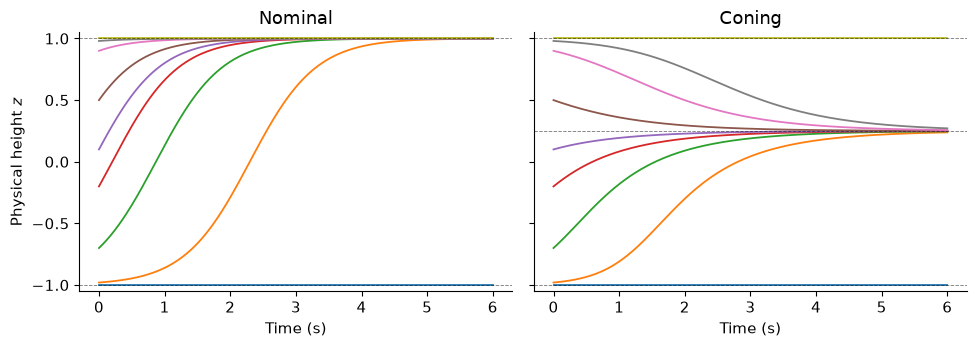

In [2]:
def height_rhs(t, z, policy):
    gain, _ = ac.gain(z, policy)
    return gain * (1 - z*z)

times = np.linspace(0, 6, 301)
starts = np.array([-1., -.98, -.7, -.2, .1, .5, .9, .98, 1.])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, policy in zip(axes, ac.POLICIES):
    sol = solve_ivp(lambda t, z: height_rhs(t, z, policy), (0, 6), starts,
                    t_eval=times, rtol=1e-10, atol=1e-12)
    assert sol.success
    for curve in sol.y:
        ax.plot(times, curve, linewidth=1.3)
    fixed = [-1, 1] if policy == "nominal" else [-1, .25, 1]
    for z in fixed:
        ax.axhline(z, color="black", linestyle="--", linewidth=.65, alpha=.5)
    ax.set(title=policy.capitalize(), xlabel="Time (s)", ylim=(-1.05, 1.05))
axes[0].set_ylabel("Physical height $z$")
fig.tight_layout()
for suffix in ("pdf", "svg"):
    fig.savefig(run.out / f"height-trajectories.{suffix}", bbox_inches="tight")
plt.show()

### Closed-loop checks

The scalar trajectories describe the invariant subsystem. The next cell checks the full simulator against the closed-loop identities derived above and compares integration at two step sizes. The reported residuals measure agreement on the tested states.

For the coning orbit, the Floquet multipliers measure how perturbations change over one revolution. The multiplier 1 corresponds to displacement along the orbit. The remaining multipliers have magnitude below 1, indicating transverse contraction in the reduced variables $(q,\eta)$. Compare the numerical values with the exact values in the last column.

In [3]:
display(run.system())

check,nominal,coning,bound or exact value
"max |η' + 2η|, closed-loop identity",2.44249e-14,1.68754e-14,< 1e-11
max |q' − V_a(q) − η × q|,4.44089e-15,4.44089e-15,< 1e-11
"equivariance of q, η, q' and M, max error",4.21885e-15,4.55191e-15,< 1e-11
"RK4 with steps 0.001 and 0.002, max difference over 1 s",4.39719e-10,3.69877e-10,< 2e-7
"observed axis against the flow of V_a on η = 0, max error over 1 s",8.29464e-11,8.90189e-11,< 2e-7
"|η(t) − exp(−2t) η(0)| for |η(0)| ≤ 6 over 20 s, max",9.96767e-10,7.32324e-10,< 2e-7
period of the coning orbit C,,1.38629,2 log 2 = 1.38629
"Floquet multipliers of C in (q, η)",,"0.0625, 0.0625, 0.0625, 0.272627, 1","1, exp(−15 log 2/8) = 0.272627, 1/16 three times"


The fixed heights provide a simpler check of the scalar dynamics. The next table evaluates the time-one map $h_1$ and its derivative at each fixed height $z_*$. The image should equal $z_*$. A derivative below 1 means nearby heights approach it, while a derivative above 1 means they move away. The difference-quotient column checks the derivative numerically.

For nominal control, the north pole attracts and the south pole repels. For coning, both poles repel and the interior height $1/4$ attracts. The latter represents a rotating circle on the sphere.

In [4]:
display(run.reference_map())

gain,fixed set,height z*,h₁(z*),h₁'(z*) = exp(g'(z*)),difference quotient,
nominal,S,-1,-1,7.38906,7.38906,repelling
nominal,N,1,1,0.135335,0.135335,attracting
coning,S,-1,-1,12.1825,12.1825,repelling
coning,C,0.25,0.25,0.391606,0.391606,attracting
coning,N,1,1,4.48169,4.48169,repelling


## Encoder, time-step map, and decoder

The encoder maps observations to a latent sphere equivariantly: rotating the plant about the vertical rotates the latent vector by the same angle. Taking its height then reduces the dynamics to an interval. 

Let $o=(p,v,Re_1,Re_2,Re_3,\Omega)\in\mathcal O\subset\mathbb R^{18}$ be the observation. The thrust-direction target $q(o)=Re_3$ occupies entries `12:15` of the observation. For rotation $Q$ about the vertical, the first five vector blocks rotate by $Q$ and body angular velocity stays fixed. The EMLP representation enforces this action. An EMLP is a neural network whose layers commute with the specified group action.

The encoder $E:\mathcal O\to Z=S^2$ and decoder $D:Z\to S^2$ have raw equivariant networks $N_E,N_D$:
$$E(o)=\nu\bigl(N_E(S^{-1}(o-\mu_o))\bigr),\qquad D(\ell)=\nu(N_D(\ell)),\qquad
\nu(y)=\frac{y}{\max(\|y\|,10^{-12})}.$$
The saved mean $\mu_o$ and diagonal scale $S$ come from training observations. For each of the first five vector blocks, only its vertical mean is removed and one RMS scale is shared across the block. Body-rate entries use componentwise means and standard deviations. The thrust-direction block uses mean zero and scale one. These operations respect the group action. Unit output requires the raw norm to be at least the numerical floor. The held-out checks test this condition on sampled inputs; global nonvanishing is not established.

Here $\ell=(\ell_1,\ell_2,\zeta)\in Z$ denotes a latent vector. The learned map $f:Z\to Z$ advances **0.1 seconds**. Its scalar network outputs $B(\zeta),A(\zeta)$, from which we define
$$b(\zeta)=0.5\tanh B(\zeta),\qquad \alpha(\zeta)=\tanh A(\zeta).$$
Writing $d(\zeta)=\cosh b(\zeta)+\zeta\sinh b(\zeta)$, the full map is
$$f(\ell)=\frac{1}{d(\zeta)}\begin{pmatrix}
\cos\alpha(\zeta)\,\ell_1-\sin\alpha(\zeta)\,\ell_2\\
\sin\alpha(\zeta)\,\ell_1+\cos\alpha(\zeta)\,\ell_2\\
\zeta\cosh b(\zeta)+\sinh b(\zeta)
\end{pmatrix}.$$
The denominator is positive on $[-1,1]$, and this formula preserves the sphere and fixes both poles. Its height map is
$$\bar f(\zeta)=\frac{\zeta\cosh b(\zeta)+\sinh b(\zeta)}{d(\zeta)}.$$
Interior fixed heights satisfy $b(\zeta)=0$. The angle $\alpha(\zeta)$ determines the rotation along each such circle. The desired prediction is $D(f^j(E(o_0)))\approx q(o_j)$ for observations $0.1j$ seconds apart.

### Learned interval coordinate

The height projection is $\pi_Z(\ell)=\zeta$. A learned increasing piecewise-linear homeomorphism $\psi:[-1,1]\to[-1,1]$ gives $u=\psi(\zeta)$. Its 33 equally spaced input knots are $\kappa_i=-1+i/16$, $i=0,\ldots,32$. A scalar network $c$ defines positive increments
$$\delta_i=\exp\!\left(0.35\tanh c\left(\frac{\kappa_i+\kappa_{i+1}}2\right)\right),\qquad
\psi(\kappa_j)=-1+2\frac{\sum_{i<j}\delta_i}{\sum_{i=0}^{31}\delta_i}.$$
Linear interpolation defines $\psi$ between knots. Positive increments guarantee an increasing inverse. A separate interval decoder $\rho:[-1,1]\to[-1,1]$ uses the same construction with its own network. It is trained to recover latent height independently of $\psi^{-1}$.

The interval encoder is $\psi\circ\pi_Z\circ E$, and its time-step map is $\psi\circ\bar f\circ\psi^{-1}$. Thus $\pi_Z\circ f=\bar f\circ\pi_Z$ holds by construction. The topological computation uses $(\psi\circ\bar f\circ\psi^{-1})^{10}$, corresponding to one second. Comparisons with the physical dynamics therefore involve three coordinates: physical height $z$, encoded height $\zeta$, and interval coordinate $u$.

## Training objective

Let $o_j$ be an observation at time $t+0.1j$, with $j\in\mathcal H=\{0,1,4,10\}$. Define $q_j=q(o_j)$, $\ell_j=E(o_j)$, $\widehat\ell_j=f^j(E(o_0))$, $\zeta_j=\pi_Z(\ell_j)$, and $\widehat\zeta_j=\pi_Z(\widehat\ell_j)$. Predictions use $\mathcal H_+=\{1,4,10\}$. For vector errors, squared norms below are divided by three to match the code's mean over coordinates. Every expectation is an empirical average over the batch and the indicated horizons.

| Term | Formula | Purpose |
|---|---|---|
| Reconstruction | $L_{\rm rec}=\mathbb E\Vert D(\ell_0)-q_0\Vert ^2/3$ | Recover the initial thrust direction |
| Prediction | $L_{\rm pred}=\mathbb E_{j\in\mathcal H_+}\Vert D(\widehat\ell_j)-q_j\Vert ^2/3$ | Predict future thrust directions |
| Encoder supervision | $L_{\rm cal}=\mathbb E_{j\in\mathcal H}\Vert \ell_j-q_j\Vert ^2/3$ | Keep the latent vector close to the known thrust direction |
| Latent consistency | $L_{\rm con}=\mathbb E_{j\in\mathcal H_+}\Vert \widehat\ell_j-\ell_j\Vert ^2/3$ | Match predicted and encoded latent states |
| Height reconstruction | $L_{\rm hr}=\mathbb E_{j\in\mathcal H}(\rho(\psi(\zeta_j))-\zeta_j)^2$ | Decode the interval coordinate |
| Height prediction | $L_{\rm hp}=\mathbb E_{j\in\mathcal H_+}(\rho(\psi(\widehat\zeta_j))-\zeta_j)^2$ | Predict latent height |
| Interval consistency | $L_{\rm ic}=\mathbb E_{j\in\mathcal H_+}(\psi(\widehat\zeta_j)-\psi(\zeta_j))^2$ | Compare predictions in the learned interval coordinate |

The joint objective is
$$L=L_{\rm rec}+3L_{\rm pred}+2L_{\rm cal}+0.5(L_{\rm con}+L_{\rm hr}+L_{\rm hp})+0.1L_{\rm ic}.$$
The first 1,000 updates instead use $L_{\rm rec}+4L_{\rm cal}+0.5L_{\rm hr}$. The loss is implemented in `_pieces` in `morsegraphs/attitude_control.py`. Supervision by the known thrust direction ties the latent representation to the prescribed physical reduction.

## Saved models and training settings

The sphere networks have width 64 and two hidden layers. Scalar networks have width 24 and two hidden layers. Training uses batches of 256, 1,000 initial calibration updates, and the joint objective through update 6,000. AdamW uses weight decay $10^{-6}$, gradient-norm clipping at 1, and a cosine learning rate from $0.002$ to $0.00005$.

Five seeds were fitted for each controller. Checkpoints and seeds were selected by the joint validation objective before any graph computation. The model-selection table reports the validation and test errors for all five fits.


Each controller has 8,192 training, 2,048 validation, and 4,096 test trajectories, with 33 observations at 0.1-second spacing. The splits contain independent trajectories. Initial conditions satisfy $\eta=0$, with independent translation and heading. A quarter start at heights within $10^{-7}$ to $10^{-2}$ of a pole.

The observation is $o=(p,v,Re_1,Re_2,Re_3,\Omega)\in\mathcal O\subset\mathbb R^{18}$. The simulator uses fourth-order Runge–Kutta with step 0.002 seconds and normalizes the orientation quaternion at each step. The saved data are checked against their metadata.

The next cell loads the bundled trajectories. Each table row gives the trajectory count and checksum comparison for one controller and data split. Matching checksums identify the data used in the subsequent model evaluation.

In [5]:
display(run.data_files())

gain,split,trajectories,observations each,generator seed,file SHA-256 (first 16),checksum matches
nominal,train,8192,33,2026111311,0605d9b527cf9e0e,yes
nominal,validation,2048,33,2026111312,5ffea67d149ac624,yes
nominal,test,4096,33,2026111323,5d72f2ebe100334a,yes
coning,train,8192,33,2026111311,4ece231f0ee49168,yes
coning,validation,2048,33,2026111312,816e5300fb27b72d,yes
coning,test,4096,33,2026111323,80202008e63764f7,yes


### Selecting the saved models

A seed specifies the random initialization and sampling used during training. The next table lists five fitted models for each controller, ranked by their saved validation objective. The lowest validation objective selects the model used below. The test errors are reported for comparison and do not determine selection.

These are stored training results. The prediction errors in the next section will be recomputed from the selected weights.

In [6]:
display(run.seeds())

gain,fit,rank,validation objective,test objective,one-second axis RMS (test),best step,
nominal,nominal-seed0,1,2.02913e-06,1.98303e-06,0.00100549,6000,selected
nominal,nominal-seed4,2,3.23482e-06,3.28029e-06,0.00106404,6000,
nominal,nominal-seed2,3,3.80302e-06,3.64327e-06,0.00124772,6000,
nominal,nominal-seed1,4,3.95735e-06,3.91036e-06,0.00143109,6000,
nominal,nominal-seed3,5,5.26517e-06,5.29802e-06,0.00133432,6000,
coning,coning-seed0,1,7.18928e-06,6.96636e-06,0.00183077,6000,selected
coning,coning-seed3,2,8.35951e-06,8.20601e-06,0.00151426,6000,
coning,coning-seed2,3,9.32044e-06,9.16698e-06,0.00173309,6000,
coning,coning-seed1,4,9.82513e-06,9.67018e-06,0.00206042,6000,
coning,coning-seed4,5,0.867251,0.868003,0.254183,6000,


The next cell loads the selected weights for each controller. Its table identifies the model and checks its weight-file checksum. With `MODE = "replay"`, this step performs no optimization and does not change the weights.

In [7]:
display(run.fits())

gain,fit,folder,weights SHA-256 (first 16),check
nominal,nominal-seed0,data/ex3_attitude_control/models/nominal-seed0,796adf953f3c85e7,file SHA-256 equals config.json: yes
coning,coning-seed0,data/ex3_attitude_control/models/coning-seed0,bd7f09f667f55578,file SHA-256 equals config.json: yes


## Model evaluation

For test observations $o_0,o_{10}$ one second apart, the thrust-direction error is
$$\sqrt{\mathbb E\|D(f^{10}(E(o_0)))-q(o_{10})\|^2/3}.$$
The average is over held-out trajectories initialized on $\eta=0$. The same time-0.1 map is applied ten times without resetting to observations. This is a componentwise error in the unit thrust-direction vector. Angular distance and full-state prediction error are different quantities. The error curves show all available horizons. The table also reports the objective and sampled checks of equivariance and sphere normalization.

In [8]:
diagnostic_arrays = {}
for policy in ac.POLICIES:
    # fits() has loaded the selected model and data into these analysis records.
    analysis = run._analyses[policy]
    result = ac.diagnostics(analysis.model, analysis.data)
    diagnostic_arrays[policy] = result.pop("arrays")
    # Retain the same diagnostics for the tables and final reference comparison.
    analysis.__dict__["diagnostics"] = result
print("Evaluated both selected models on the held-out trajectories.")

Evaluated both selected models on the held-out trajectories.


The next plot uses those recomputed predictions. Each curve gives the componentwise RMS error over the test trajectories at the indicated forecast horizon. At time zero, the error comes from encoding and decoding the initial observation. At later times, it also includes repeated application of the learned map.

Comparing the curves at a fixed horizon shows how prediction accuracy differs between the two controllers.

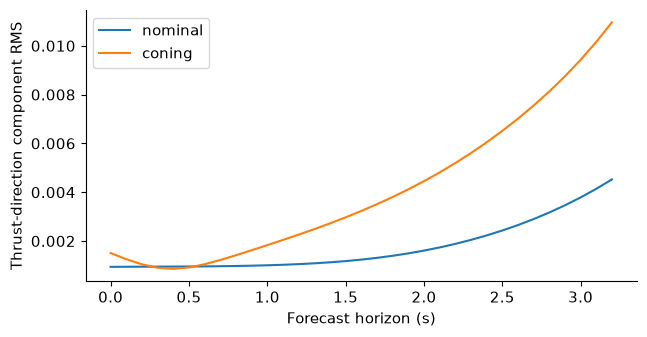

In [9]:
fig, ax = plt.subplots(figsize=(6.6, 3.5))
for policy, arrays in diagnostic_arrays.items():
    errors = arrays["forecast_rms"]
    ax.plot(.1*np.arange(len(errors)), errors, label=policy)
ax.set(xlabel="Forecast horizon (s)", ylabel="Thrust-direction component RMS")
ax.legend()
fig.tight_layout()
for suffix in ("pdf", "svg"):
    fig.savefig(run.out / f"prediction-errors.{suffix}", bbox_inches="tight")
plt.show()

The table below summarizes the same evaluation and adds consistency checks. “Latent closure” compares a predicted latent state with the encoded future observation. The equivariance residual tests whether rotating an input commutes with the learned maps on sampled states.

The final row tests the cell-image hulls against a denser sample. Zero excess means that every tested image lies in its hull. This sampled check does not establish enclosure of all images.

In [10]:
display(run.errors())

quantity,nominal,coning,Section 5.3
"one-second axis RMS, componentwise (test trajectories)",0.00100553,0.00183081,below 0.002
validation objective,2.02909e-06,7.18923e-06,
test objective,1.98301e-06,6.96633e-06,
"axis prediction RMS at 1, 4 and 10 steps (test windows)",0.000498411,0.00103315,
"latent closure RMS at 1, 4 and 10 steps (test windows)",0.000643256,0.00127476,
fixed heights of fbar between the poles,,0.247074,
"sampled equivariance error of E and f, max",1.40404e-07,1.47072e-07,
"image hulls against 4,097 samples per cell, largest excess",0,0,≤ 0


### Physical, latent, and interval coordinates

Each row uses the selected model for one controller. The left panel compares physical height $z=q_3$ with encoded latent height $\zeta=\pi_Z(E(o))$ on test observations. Encoder supervision encourages proximity to the diagonal but does not impose equality. The middle panel shows $u=\psi(\zeta)$. The right shows the one-step height displacement $\bar f(\zeta)-\zeta$, whose zeros are fixed latent heights. The later graph computation uses ten steps.

In the displacement panel, a positive displacement moves height upward and a negative displacement moves it downward. A zero with positive displacement to its left and negative displacement to its right is attracting in height.

The cell uses the arrays computed above and checks that $\psi$ is increasing and fixes both endpoints.

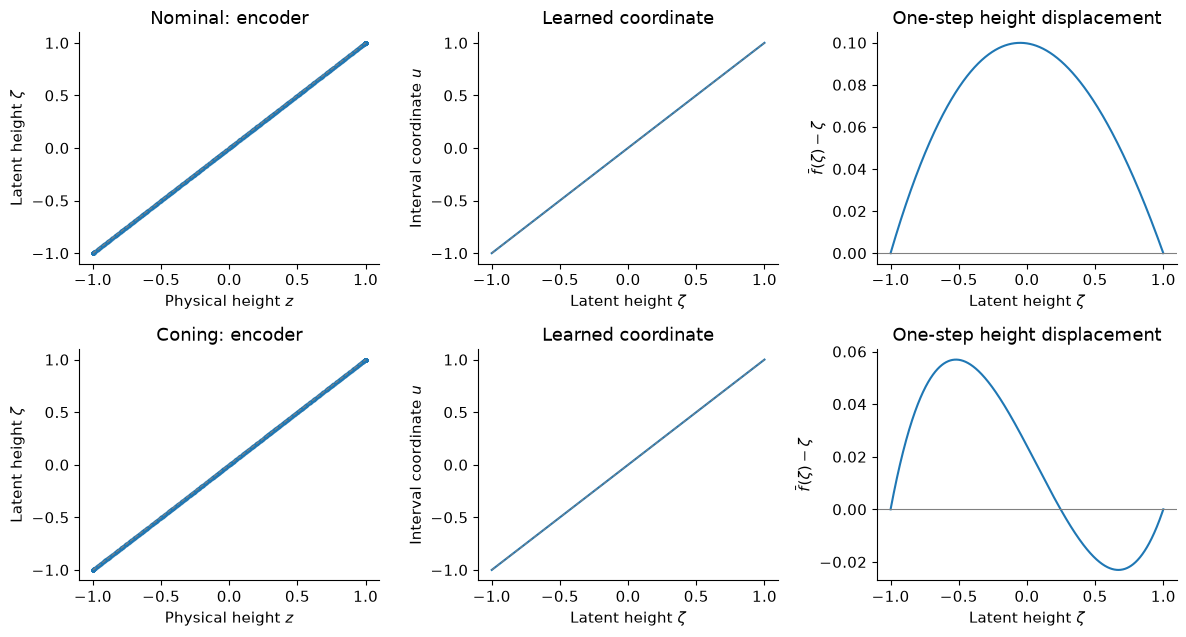

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for row, policy in enumerate(ac.POLICIES):
    arrays = diagnostic_arrays[policy]
    heights = arrays["heights"]
    knots, values = arrays["knots"], arrays["coordinate_values"]
    assert np.all(np.diff(values) > 0)
    np.testing.assert_allclose(values[[0, -1]], [-1, 1], atol=1e-7)
    ax = axes[row, 0]
    ax.scatter(arrays["test_physical_axis"][:, 2], arrays["test_latent_axis"][:, 2],
               s=3, alpha=.2, rasterized=True)
    ax.plot([-1, 1], [-1, 1], color=".5", linestyle="--", linewidth=.8)
    ax.set(xlabel="Physical height $z$", ylabel=r"Latent height $\zeta$",
           title=f"{policy.capitalize()}: encoder")
    ax = axes[row, 1]
    ax.plot(knots, values)
    ax.plot([-1, 1], [-1, 1], color=".5", linestyle="--", linewidth=.8)
    ax.set(xlabel=r"Latent height $\zeta$", ylabel="Interval coordinate $u$",
           title="Learned coordinate")
    ax = axes[row, 2]
    ax.plot(heights, arrays["latitude"] - heights)
    ax.axhline(0, color=".5", linewidth=.8)
    ax.set(xlabel=r"Latent height $\zeta$", ylabel=r"$\bar f(\zeta)-\zeta$",
           title="One-step height displacement")
fig.tight_layout()
for suffix in ("pdf", "svg"):
    fig.savefig(run.out / f"coordinate-diagnostics.{suffix}", bbox_inches="tight")
plt.show()

## Morse graphs and indices

Partition $[-1,1]$ into 128 cells. For each cell, sample the time-one height map at 257 points, take the minimum and maximum images, expand that interval by $2\times10^{-6}$, and clip it to $[-1,1]$. A directed edge joins the source cell to every cell meeting its image interval. These sampled hulls are not validated enclosures.

A Morse component consists of recurrent, mutually reachable cells. CMGDB represents each component by a node and records reachability between nodes. A minimal node has no outgoing path to another node. The resulting graph describes the finite cell relation. Its arrows alone do not prove connecting trajectories of the physical system.

CMGDB also computes Conley indices over $\mathbb F_5$, the field of integers modulo five. For an index pair $(N,L)$, the relevant groups are $H_k(N,L;\mathbb F_5)$, the homology of an isolating neighborhood relative to its exit set. The displayed tuples list the surviving index-map polynomials in degrees 0 and 1. Here `x-1` denotes one class with identity action, while `0` denotes a trivial Conley-index entry. The polynomial variable `x` is not a state coordinate.

### Learned graph and grouping

The interval encoder is $\psi\circ\pi_Z\circ E$, where $\pi_Z(\ell)=\zeta$ and $u=\psi(\zeta)$. CMGDB analyzes the tenth iterate of $\psi\circ\bar f\circ\psi^{-1}$, corresponding to one second, on the same 128-cell interval grid.

For coning, the physical dynamics have two repelling poles and one attracting latitude. The learned cell graph has four components: one at each pole, an attracting interior component, and a small adjacent component. To compare with the physical picture, we group the two interior components together with all cells on paths between them. This gives a coarser description of the computed dynamics, with one interior node representing the combined set.

The code checks that the group contains one minimal component, that no edge leaves it, and that the connecting paths stay within the group. It recomputes the index on the combined region. The adjacent component has zero index, but that does not establish that it contains no dynamics. The raw graph distinguishes the two interior components, while the grouped graph describes their union together with the connecting cells. The residual comparison below concerns the attracting region of this combined set.

First compute the graph of the known scalar dynamics in physical height. Each row below is one Morse component. “Cells cover” gives the interval occupied by its cells, and “edges to” lists downstream components. An empty entry means that component has no outgoing edge to another component.

In [12]:
display(run.reference_graphs())

gain,Morse set,cells,"cells cover, in z",Conley index (CMGDB),edges to
nominal,S,1,"[-1, -0.984375]","(0, 0)",N
nominal,N,1,"[0.984375, 1]","(x-1, 0)",
coning,S,1,"[-1, -0.984375]","(0, 0)",C
coning,C,2,"[0.234375, 0.265625]","(x-1, 0)",
coning,N,1,"[0.984375, 1]","(0, 0)",C


Now compute the learned graph in the interval coordinate $u$. “Raw” lists the components before grouping, and “merged” lists the result after grouping. The last column identifies which original components belong to each merged node.

For coning, the two interior raw components form a single merged component with a recomputed index. The intervals are expressed in $u$; comparison with physical heights requires the corresponding change of coordinates.

In [13]:
display(run.learned_graphs())

gain,graph,Morse set,cells,"cells cover, in u",Conley index (CMGDB),edges to,Morse sets of the raw graph
nominal,raw,S,1,"[-1, -0.984375]","(0, 0)",N,
nominal,raw,N,1,"[0.984375, 1]","(x-1, 0)",,
nominal,merged,S,1,"[-1, -0.984375]","(0, 0)",N,S
nominal,merged,N,1,"[0.984375, 1]","(x-1, 0)",,N
coning,raw,S,1,"[-1, -0.984375]","(0, 0)",C,
coning,raw,C,1,"[0.234375, 0.25]","(x-1, 0)",,
coning,raw,A,1,"[0.25, 0.265625]","(0, 0)",C,
coning,raw,N,1,"[0.984375, 1]","(0, 0)",A,
coning,merged,S,1,"[-1, -0.984375]","(0, 0)",C,S
coning,merged,C,2,"[0.234375, 0.265625]","(x-1, 0)",,"C, A"


### Comparison with the reference

The physical and learned graphs must be compared in corresponding coordinates. The reference is therefore computed both in physical height $z$ and after the change of coordinate $u=\psi(z)$, using the same grid and grouping rule as the learned map.

For the selected coning fit, the reference and learned graphs in $u$ each have an additional interior component, on opposite sides of the attracting component $C$. Their grouped graphs agree, including the cells assigned to each node. Labels $S$ and $N$ denote the south and north poles, $C$ the coning component, and $A$ an additional interior component.

Read the final column as three separate comparisons: “order” checks graph reachability, “indices” checks the index labels, and “cells” checks the assigned cells when both graphs use the same coordinate. The raw coning graphs differ in order and cell assignment, while the grouped graphs agree. A blank comparison entry denotes a learned graph being used as the comparison target.

In [14]:
display(run.comparison())

gain,graph,Morse sets and indices,order,Morse sets between the poles,agrees with the learned graph of its kind
nominal,reference in z,"S (0, 0), N (x-1, 0)",S → N,,order yes; indices yes
nominal,"reference in ψ, raw","S (0, 0), N (x-1, 0)",S → N,,order yes; indices yes; cells yes
nominal,"reference in ψ, merged","S (0, 0), N (x-1, 0)",S → N,,order yes; indices yes; cells yes
nominal,"learned, raw","S (0, 0), N (x-1, 0)",S → N,,
nominal,"learned, merged","S (0, 0), N (x-1, 0)",S → N,,
coning,reference in z,"S (0, 0), C (x-1, 0), N (0, 0)","S → C, N → C","C [0.234375, 0.265625]",order yes; indices yes
coning,"reference in ψ, raw","S (0, 0), A (0, 0), C (x-1, 0), N (0, 0)","A → C, S → A, N → C","C [0.25, 0.265625], A [0.234375, 0.25]",order no; indices yes; cells no
coning,"reference in ψ, merged","S (0, 0), C (x-1, 0), N (0, 0)","S → C, N → C","C [0.234375, 0.265625]",order yes; indices yes; cells yes
coning,"learned, raw","S (0, 0), C (x-1, 0), A (0, 0), N (0, 0)","S → C, A → C, N → A","C [0.234375, 0.25], A [0.25, 0.265625]",
coning,"learned, merged","S (0, 0), C (x-1, 0), N (0, 0)","S → C, N → C","C [0.234375, 0.265625]",


### Reconstructed indices on the sphere

An interior quotient height represents a circle, while an endpoint represents a single pole. Recovering a sphere index therefore requires more than reusing the interval index.

The reconstruction theorem in the paper's appendix combines the quotient index on $(N/G,L/G)$ with the index relative to $K/G$, where $K=L\cup(N\cap P)$ and $P/G=\{-1,1\}$ consists of the fixed poles. Here the orbit dimension is one and the degree on the circle is one. [`reconstructed_index`](morsegraphs/homology.py) computes these two index maps from the cell relation and combines them to obtain the lifted index.

The table compares these computations with the physical thrust-axis indices derived from explicit index pairs in the paper. A repelling pole has $H_2(N,L;\mathbb F_5)\cong\mathbb F_5$, the upright sink has $H_0(N,L;\mathbb F_5)\cong\mathbb F_5$, and the attracting coning circle has nonzero groups in degrees 0 and 1. The corresponding nonzero index maps are identities. For the learned graph, the reconstruction concerns the lifted cell model. Agreement with the physical indices is a numerical comparison, not a certified identification of physical invariant sets.

In the next table, the two interval-index columns compare CMGDB with the separate homology computation. The reconstructed sphere index is then compared with the analytical index. The “cells of N_P/G” column counts cells of the index neighborhood on the fixed-pole stratum. An interior component has none. The “agree” column compares the index tuples.

In [15]:
display(run.indices())

gain,graph,Morse set,"index on [-1, 1] (CMGDB)","index on [-1, 1] (homology)",cells of N_P/G,index in S² (reconstructed),index in S² (proved),agree
nominal,reference in z,S,"(0, 0)","(0, 0)",1,"(0, 0, x-1)","(0, 0, x-1)",yes
nominal,reference in z,N,"(x-1, 0)","(x-1, 0)",1,"(x-1, 0, 0)","(x-1, 0, 0)",yes
nominal,"reference in ψ, merged",S,"(0, 0)","(0, 0)",1,"(0, 0, x-1)","(0, 0, x-1)",yes
nominal,"reference in ψ, merged",N,"(x-1, 0)","(x-1, 0)",1,"(x-1, 0, 0)","(x-1, 0, 0)",yes
nominal,"learned, merged",S,"(0, 0)","(0, 0)",1,"(0, 0, x-1)","(0, 0, x-1)",yes
nominal,"learned, merged",N,"(x-1, 0)","(x-1, 0)",1,"(x-1, 0, 0)","(x-1, 0, 0)",yes
coning,reference in z,S,"(0, 0)","(0, 0)",1,"(0, 0, x-1)","(0, 0, x-1)",yes
coning,reference in z,C,"(x-1, 0)","(x-1, 0)",0,"(x-1, x-1, 0)","(x-1, x-1, 0)",yes
coning,reference in z,N,"(0, 0)","(0, 0)",1,"(0, 0, x-1)","(0, 0, x-1)",yes
coning,"reference in ψ, merged",S,"(0, 0)","(0, 0)",1,"(0, 0, x-1)","(0, 0, x-1)",yes


## Graphs and sphere preimages

### Nominal control

(a) The grouped learned interval graph, with its computed indices. (b) The preimages of its cells under $\psi\circ\pi_Z$ on the latent sphere, with the Morse components in solid colors and the attracting region in a lighter tint. (c) The same graph with reconstructed sphere indices.

The attractor is green. The repelling south pole is vermilion. The graph runs from $S$ to the upright sink $N$. Panel (b) represents cells on the latent sphere through $\psi\circ\pi_Z$. Pullback to plant observations would additionally require the encoder $E$. The cell saves PDF and SVG panels under `OUT/figures/attitude/nominal/`.

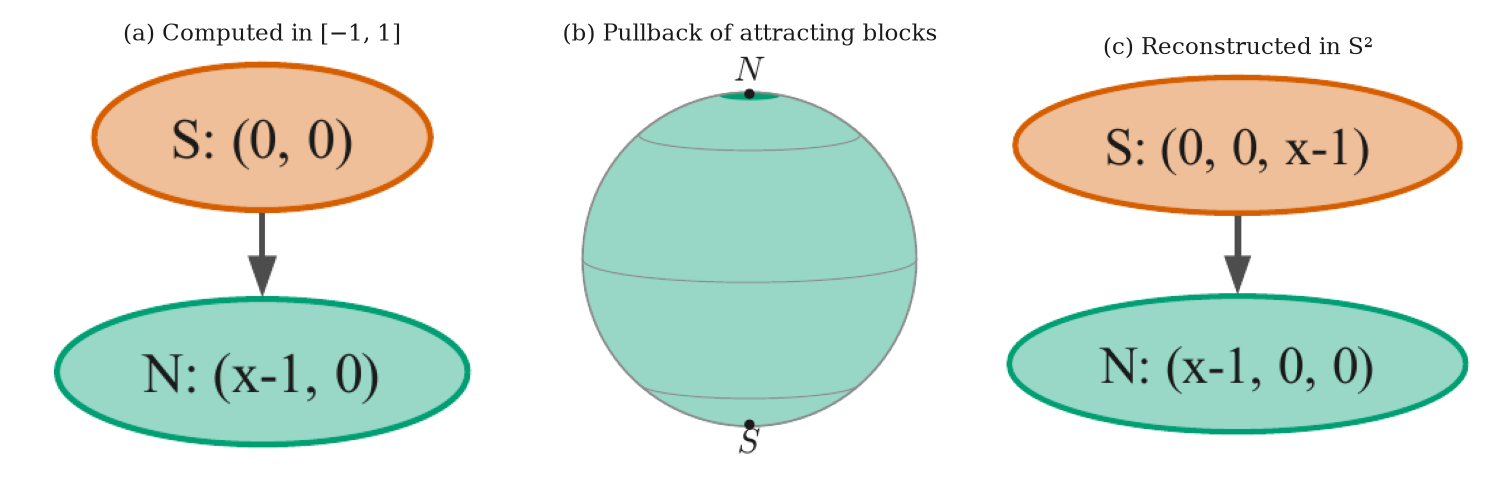

In [16]:
run.figure_nominal()

### Coning control

The panels have the same meaning as above. Both poles lead to the attracting coning component. The repelling north pole is orange, and the attracting component is green. Panel (b) shows the grouped region used in the tolerance comparison. The panels are saved under `OUT/figures/attitude/coning/`.

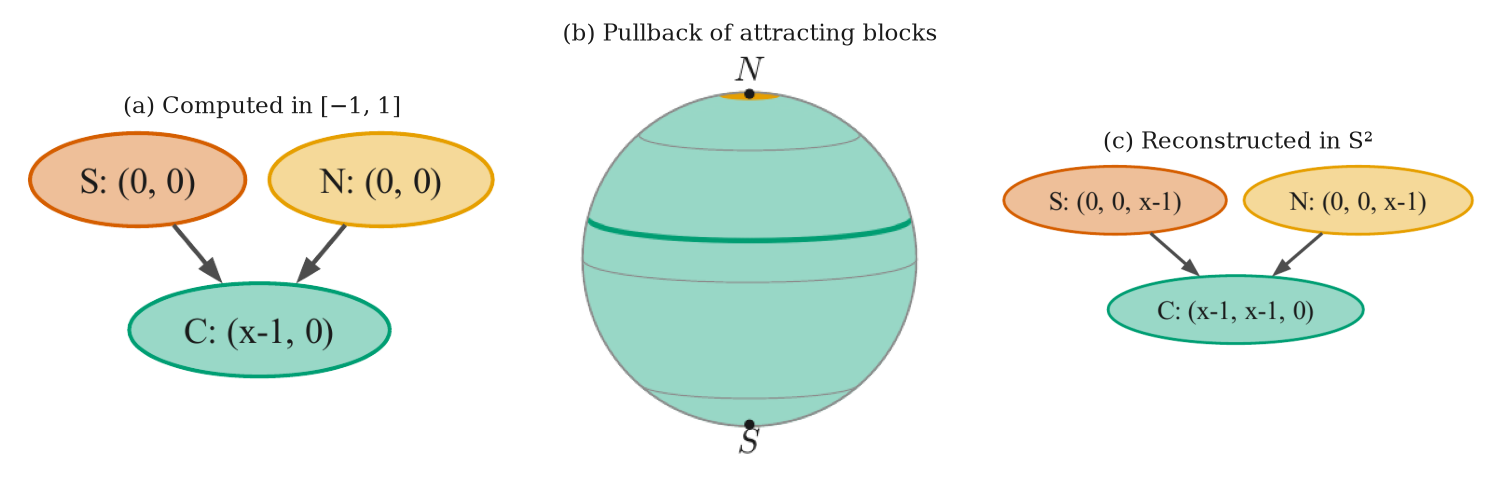

In [17]:
run.figure_coning()

### Interval cells and their sphere preimages

Each colored interval cell $[u_-,u_+]$ corresponds to the latent-sphere band $\psi^{-1}(u_-)\leq\zeta\leq\psi^{-1}(u_+)$. The following plots place the Morse bands above their interval cells for each controller. These bands represent the Morse components. The larger attracting regions appear in the preceding sphere panels.

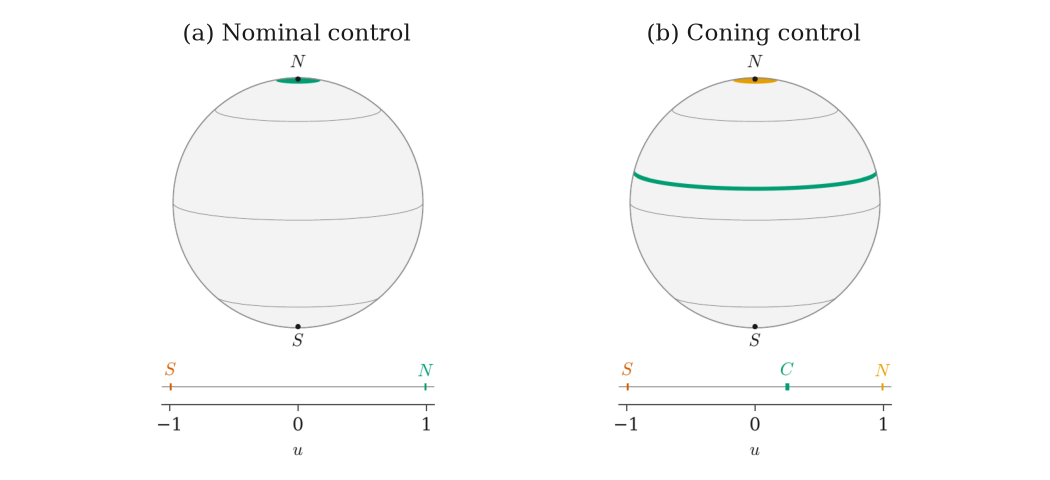

In [18]:
run.figure_appendix_spheres()

## Relation to the controlled thrust direction

### Attracting regions, tolerances, and residuals

For a minimal Morse component $\mathcal M$, collect cells from which no path of the finite graph leaves the domain or reaches another Morse component. Write $N$ for their union. After grouping, apply the same construction to the combined component. The estimated tolerance measures the distance from the sampled cell-image hulls to the complement of $N$. It measures how much room the predicted images have before reaching the region boundary.

To compare this tolerance with prediction error, use one-second observation pairs $(o,o')$ whose initial encoded interval coordinate lies in $N$. The residual compares $\bar f^{10}(\pi_ZE(o))$ with $\pi_ZE(o')$. Both tolerance and residual use the quotient of the chordal metric on the latent sphere, after undoing $\psi$. For heights $s,t$, this distance is
$$d(s,t)=\sqrt{(s-t)^2+\bigl(\sqrt{1-s^2}-\sqrt{1-t^2}\bigr)^2}.$$
It is the minimum Euclidean distance between the corresponding latitude circles.

The last column asks whether the largest sampled prediction residual is smaller than this estimated tolerance. For coning before grouping, the residual is about 0.0149 and the tolerance about 0.00181, so the comparison fails. The sampled error exceeds the margin available in this region, leaving the comparison inconclusive about its pullback to the physical dynamics.

Before grouping, cells that can reach the adjacent component are excluded from the attracting region. Grouping includes those cells and gives a larger region whose predicted images lie farther from its boundary. The estimated tolerance rises to about 0.172, while the sampled residual remains about 0.0149. The grouped region therefore passes this numerical comparison. This conclusion concerns the combined region. Since both the image hulls and residual maxima come from samples, it is not a uniform guarantee for the physical system.

Read each row as one attracting region. “N in u” gives its interval extent, and “samples” counts the observation pairs used in that row. Compare the raw and merged coning rows to see the change in the region and tolerance. The nominal graph is unchanged by grouping.

In [19]:
display(run.regions())

gain,minimal Morse set (Morse sets of the raw graph),graph,cells of 𝒜,N in u,samples in E⁻¹(N),tolerance,max residual,residual < tolerance
nominal,N (N),merged,127,"[-0.984375, 1]",87450,0.294831,0.0148708,yes
coning,"C (C, A)",merged,126,"[-0.984375, 0.984375]",76823,0.172168,0.0148951,yes
coning,C (C),raw,79,"[-0.984375, 0.25]",48090,0.00180907,0.0148951,no


The learned models reproduce the nominal graph and, after grouping, the coning graph. For both controllers, the sampled residual lies below the estimated tolerance of the reported attracting region.

## Reproducibility check

The final cell saves this run's numerical record to `OUT/results.json` and compares it with the bundled reference. It requires exact graph agreement and numerical agreement to relative tolerance $10^{-6}$. It does not train a model or update the reference.

The comparison status is saved in `OUT/replay-check.json`. A failed comparison is displayed below, including the first differing entries, without interrupting the figure walkthrough. Other computation errors still raise normally.

In [20]:
import json

try:
    check_result = run.check()
except AssertionError as error:
    # Handle only the completed reference comparison, not a computation error.
    status = run._check
    if not status or status.get("passed") is not False or not str(error).startswith("The replay differs from "):
        raise
    print("Reference comparison: FAILED")
    print(str(error))
else:
    display(check_result)

check_path = run.out / "replay-check.json"
check_path.write_text(json.dumps(run._check, indent=2) + "\n")
print(f"Comparison report: {run.rel(check_path)}")

Reference comparison: FAILED
The replay differs from data/ex3_attitude_control/reference/results.json in 177 places: ['/coning/diagnostics/closure_rms_by_horizon/1: 0.0005117679829709232 against 0.0005117712425999343', '/coning/diagnostics/closure_rms_by_horizon/2: 0.0009027900523506105 against 0.0009027955238707364', '/coning/diagnostics/closure_rms_by_horizon/3: 0.001179973129183054 against 0.0011799795320257545', '/coning/diagnostics/closure_rms_by_horizon/4: 0.001369571196846664 against 0.0013695759698748589', '/coning/diagnostics/closure_rms_by_horizon/6: 0.0016740557039156556 against 0.0016740472055971622']
Comparison report: outputs/notebooks/ex3_attitude_control-replay-20261114-044308/replay-check.json
